# Card vs e-receipt vs Yipit: AI subscription gross adds, churn and net adds

**Goal:** compare monthly gross adds, churn and net adds per AI provider and channel across the card panel, the e-receipt panel and Yipit. The comparison covers both the level and the trend, to decide how to use or combine the two datasets in the Consumer AI web app. Plan and agreed decisions: `../plans/26th_october_2026.txt`.

**Code to review:** all SQL and rules are in **`card_ereceipt_rules.py`**. It reuses logic from these files from other workstreams:
| File | What is reused |
|---|---|
| `card_core_rules.py` | Card pull pattern: `EARNEST.COMMON.TXNS_CORE_V` for tagged rows, plus Omega `TRANS_V1_0` for untagged merchids |
| `../filters/{provider}.py` (+ `*_report.md`) | Card descriptor and price rules per provider (`classify(df, "omega")`). `chatgpt.py` matches the truncated `CHATGP` form |
| `channel_rules.py` | E-receipt gross-add series (75 / 400 days) and cancellation de-duplication (45 days) |
| `_make_direct_v_channel.py` | E-receipt sender and description filters per provider x channel (`direct_v_channel_comparison.ipynb`) |
| `../filters_receipts/grok.py` (+ `grok_report.md`) | X Premium+ receipt patterns and the SpaceXAI LLC Google Play cancellations |

**Panels**
- **Card:** Omega 2022 consistent-shopper panel (`aggregate_consistent_shopper_2022_v2`, affected accounts excluded), on both `TXNS_CORE_V` and the Omega untagged rows. **Unweighted:** each account counts as 1.
- **E-receipt:** `srs_slice.common.items_v` mailboxes with `entry_date < 2023-01-01` that are still `ACTIVE`. Mailboxes that later go inactive are dropped from all history. Email history from 2022-11 (before the panel cut-off) counts towards the subscription state.
- **Yipit:** `plans/yipitdata_consumer_ai.xlsx`, Monthly Metrics, US Subscriber Behavior. This is a provider total (not by channel) and covers ChatGPT, Gemini, Claude and Perplexity only.

**Definitions** (provider level, by channel)
| | Card | E-receipt | Yipit |
|---|---|---|---|
| Gross add | First payment with no payment for the same provider x channel in the previous 40 days (385 if that payment was annual) | First sign-up or paid email in a series for the provider x channel. A new series starts after a 75-day gap (400 after an annual), or after a cancellation | New Signup + Re-Signup + Upgrade |
| Churn | No further payment within 40 days (385 for annual), dated at last payment + 40 (385) days | Cancellation email (repeats within 45 days count once), **counted only if the mailbox had a gross add for the provider on any channel since its previous cancellation** | Churn |
| Net adds | Gross adds − churn | Gross adds − churn | Gross adds − churn |

Counts are distinct accounts or mailboxes per month, January 2024 to August 2026. August 2026 is the last month in which every 40-day card churn can be confirmed. The **Total** row is the simple sum of the channel rows, with no cross-channel de-duplication.

**Charts:** each provider section has a 4 x 3 grid. Rows are Direct/web, Google Play, iTunes and Total. Columns are gross adds, churn and net adds. Both e-receipt panels share the left axis: ours (by channel) and Yipit's provider total, which appears on every row. Card is on the right axis. Card counts are on a different scale, so compare card with the e-receipts by trend; the summary tables give the card / e-receipt level ratio. Cards cannot see Apple billing, so the iTunes row has no card line.

Muse is left out because it launched on 7–8 Sep 2026, after the window.

In [1]:
import warnings, pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.dates as mdates
from IPython.display import display, Markdown
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="This pattern is interpreted")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
import card_ereceipt_rules as R

card_raw = pd.read_parquet(R.CACHE / "card_raw.parquet") if (R.CACHE / "card_raw.parquet").exists() else R.pull_card()
rec_raw = pd.read_parquet(R.CACHE / "receipt_raw.parquet") if (R.CACHE / "receipt_raw.parquet").exists() else R.pull_receipts()
CARD_END, REC_END = card_raw.dt.max(), pd.to_datetime(rec_raw.order_date).max()
print(f"card rows {len(card_raw):,} (data end {CARD_END.date()}); e-receipt rows {len(rec_raw):,} (data end {REC_END.date()}, "
      f"{rec_raw.mailbox_id.nunique():,} panel mailboxes with an AI-related email)")

card rows 8,023,785 (data end 2026-10-25); e-receipt rows 5,221,932 (data end 2026-10-26, 344,514 panel mailboxes with an AI-related email)


### Queries
These are the queries `card_ereceipt_rules.py` runs. Delete the parquet files in `../.cache/card_ereceipt/` to re-pull (card about 10-15 minutes on `ANALYST_XL`).

In [2]:
for name in ["CARD_TXNS_CORE_SQL", "CARD_OMEGA_SQL", "RECEIPT_SQL"]:
    print(f"-- {name}", getattr(R, name), sep="\n")

-- CARD_TXNS_CORE_SQL

SELECT brand_id, transid, memid, trans_date AS dt, filedate, trans_amount AS amount, currency, transtype,
       billing_description AS descr
FROM EARNEST.COMMON.TXNS_CORE_V
WHERE weight_agg_cs2022 IS NOT NULL AND trans_date >= '2023-01-01'
  AND (brand_id IN (29847, 27440, 29069)                                  -- Anthropic, OpenAI, Perplexity
       OR (brand_id = 32111 AND trans_date >= '2024-01-01' AND ABS(trans_amount) >= 3.5))  -- Google One

-- CARD_OMEGA_SQL

WITH panel AS (
    SELECT cardlinkid FROM SHARE_CE_PRIME_ENRICHED_OMEGA_2822.PRIME_OMEGA.CARDLINK_PANEL_V1_0 p
    WHERE panel = 'aggregate_consistent_shopper_2022_v2'
      AND NOT EXISTS (SELECT 1 FROM SHARE_CE_PRIME_ENRICHED_OMEGA_2822.PRIME_OMEGA_STATIC.AFFECTED_ACCOUNTS_092026 a WHERE a.cardlinkid = p.cardlinkid)),
mids AS (
    SELECT d.merchid, d.merchdesc,
           d.merchdesc ILIKE ANY ('%grok%', '%x.ai%', '%xai %', '% xai%', '%x corp%', '%xcorp%', '%twitter%',
                          

In [3]:
pay = R.card_payments(card_raw)
spells = R.card_spells(pay, CARD_END)
card = R.card_monthly(spells)
adds, cans = R.receipt_events(rec_raw)
rec = R.receipt_monthly(adds, cans)
yip = R.yipit()
yip = yip[yip.month.isin(R.MONTHS)]

# how many cancellations the subscription-state rule removes (2024-01 to 2026-08)
c = cans[cans.dt.dt.to_period("M").isin(R.MONTHS)]
display(Markdown("**E-receipt cancellations removed because the mailbox was not subscribed (no gross add since its previous cancellation), Jan 2024 to Aug 2026**"))
display(c.groupby(["provider", "channel"]).agg(cancellations=("counted", "size"), counted=("counted", "sum"))
        .assign(removed_share=lambda t: 1 - t.counted / t.cancellations).style.format({"removed_share": "{:.1%}", "cancellations": "{:,}", "counted": "{:,}"}))

**E-receipt cancellations removed because the mailbox was not subscribed (no gross add since its previous cancellation), Jan 2024 to Aug 2026**

**Finding: the subscription-state rule removes 13-46% of e-receipt cancellations, except for Claude.**
- **Claude:** direct 1.7%, iTunes 3.1%. Its sign-ups and cancellations are both well reported.
- **ChatGPT:** direct 32%, Google Play 30%, iTunes 16%. **Gemini:** 36-46%. **Grok:** 40-46%. **Perplexity direct:** 37%.
- These are cancellations with no sign-up or paid email since the previous cancellation: missed sign-up emails (ChatGPT direct ~16% per the NIQ missing-email study), cancelled free trials (Grok, Gemini), and repeated cancel emails more than 45 days apart.

In [4]:
COL = {"E-receipt": "#2a78d6", "Card": "#eb6834", "Yipit": "#3d3d3a"}
ROWS = {"direct": "Direct / web", "google_play": "Google Play", "itunes": "iTunes (App Store)", "total": "Total (sum of channels)"}
METRICS = {"gross_adds": "Gross adds", "churn": "Churn", "net_adds": "Net adds"}

def series(t, p, ch, col):
    s = t[(t.provider == p) & (t.channel == ch)].set_index("month")[col]
    return s.reindex(R.MONTHS)

def plot_provider(p):
    y = yip[yip.provider == p].set_index("month").reindex(R.MONTHS)
    has_yipit = y.gross_adds.notna().any()
    fig, axes = plt.subplots(4, 3, figsize=(20, 15), sharex=True)
    for i, ch in enumerate(ROWS):
        for j, col in enumerate(METRICS):
            ax = axes[i, j]
            x = R.MONTHS.to_timestamp()
            e, c = series(rec, p, ch, col), series(card, p, ch, col)
            lines = []
            if e.abs().sum() > 0: lines += ax.plot(x, e.values, color=COL["E-receipt"], lw=2, label="E-receipt (left)")
            if has_yipit: lines += ax.plot(x, y[col].values, color=COL["Yipit"], lw=1.6, ls="--", label="Yipit total (left)")
            if c.abs().sum() > 0:
                ax2 = ax.twinx()
                lines += ax2.plot(x, c.values, color=COL["Card"], lw=2, label="Card (right)")
                ax2.spines[["top"]].set_visible(False); ax2.tick_params(axis="y", colors=COL["Card"], labelsize=8)
                if col != "net_adds": ax2.set_ylim(bottom=0)
                else: ax2.axhline(0, color="#f3b49a", lw=0.6, ls=":")
                if j == 2: ax2.set_ylabel("card accounts per month", color=COL["Card"])
            if not lines: ax.text(0.5, 0.5, "no data in either source", transform=ax.transAxes, ha="center", color="#888888")
            if col == "net_adds": ax.axhline(0, color="#999999", lw=0.8)
            elif lines: ax.set_ylim(bottom=0)
            ax.grid(axis="y", color="#e5e5e5", lw=0.8); ax.spines[["top"]].set_visible(False)
            ax.set_title(f"{ROWS[ch]}: {METRICS[col].lower()}", loc="left", fontsize=10)
            if j == 0: ax.set_ylabel("e-receipt mailboxes per month")
            if i == 0 and j == 0: ax.legend(handles=lines, frameon=False, loc="upper left", fontsize=8)
            ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    fig.suptitle(f"{R.NAMES[p]}: gross adds, churn and net adds by channel (e-receipt" + (" and Yipit" if has_yipit else "") + " left axis, card right axis" + ("" if has_yipit else "; no Yipit series") + ")",
                 x=0.01, ha="left", fontsize=13)
    fig.tight_layout(); plt.show()

def summary(p):
    '''Jan 2024 to Aug 2026 totals per source x channel, and the correlation of monthly series (level and month-on-month change).'''
    out = []
    for ch in ROWS:
        for col in METRICS:
            e, c = series(rec, p, ch, col), series(card, p, ch, col)
            y = yip[yip.provider == p].set_index("month")[col].reindex(R.MONTHS)
            r = {"channel": ROWS[ch], "metric": METRICS[col], "e-receipt total": e.sum() if e.abs().sum() else np.nan, "card total": c.sum() if c.abs().sum() else np.nan,
                 "card / e-receipt": c.sum() / e.sum() if e.sum() and c.abs().sum() else np.nan,
                 "corr card vs e-receipt": e.corr(c) if e.std() and c.std() else np.nan,
                 "corr MoM change card vs e-receipt": e.diff().corr(c.diff()) if e.std() and c.std() else np.nan}
            if y.notna().sum() > 6:
                r.update({"corr e-receipt vs Yipit": e.corr(y), "corr card vs Yipit": c.corr(y)})
            out.append(r)
    t = pd.DataFrame(out).set_index(["channel", "metric"])
    return t.style.format({k: "{:,.0f}" for k in ["e-receipt total", "card total"]} | {k: "{:.2f}" for k in t.columns if k.startswith(("corr", "card /"))}, na_rep="")

## 1. ChatGPT

**Channels seen:** card = web + Google Play. E-receipt = direct, Google Play, iTunes. Yipit = provider total.

**Card filter** (`../filters/chatgpt.py`). OpenAI's subscription merchids are almost all untagged in Omega (brand 27440 covers mainly the API), so most rows come from the Omega untagged pull.
- **Web:** `CHATGPT SUBSCR…`, `OPENAI *CHATGPT`, `OPENAIOPCO`, PayPal `OPENAI`, plus the truncated `CHATGP` form (no trailing T, e.g. `PAYPAL *OPENAI *CHATGP`). Bare `OPENAI` counts only when the amount is a plan price and the account repeats that plan 25–35 days apart. Otherwise it is API usage.
- **Google Play:** `GOOGLE *CHATGPT` / `GOOGLE *CHATGP`, at Play price points.
- **Plans** (all monthly): Go, Plus, Pro $100/$200/$500, including 50% promos. Team/Business seat multiples, credits and Sora are excluded.

**E-receipt filter**
- **Direct:** the `Chat GPT` (4070) sign-up email naming the plan (`ChatGPT Plus/Go/Pro subscription`). Direct sends **no renewal receipts**, so each add is a sign-up. Churn comes from `Chat GPT Cancellation` (4078) emails naming the plan.
- **Google Play:** a priced `(ChatGPT) Auto-renewing subscription` receipt each month. Churn comes from `Google Play Cancellation` emails mentioning ChatGPT.
- **iTunes:** an unpriced confirmation (`… /month`) or a priced `(Monthly)` / `(Annual)` receipt for the `ChatGPT` app, excluding credits. Churn comes from `iTunes Cancellation` `ChatGPT ChatGPT …`.

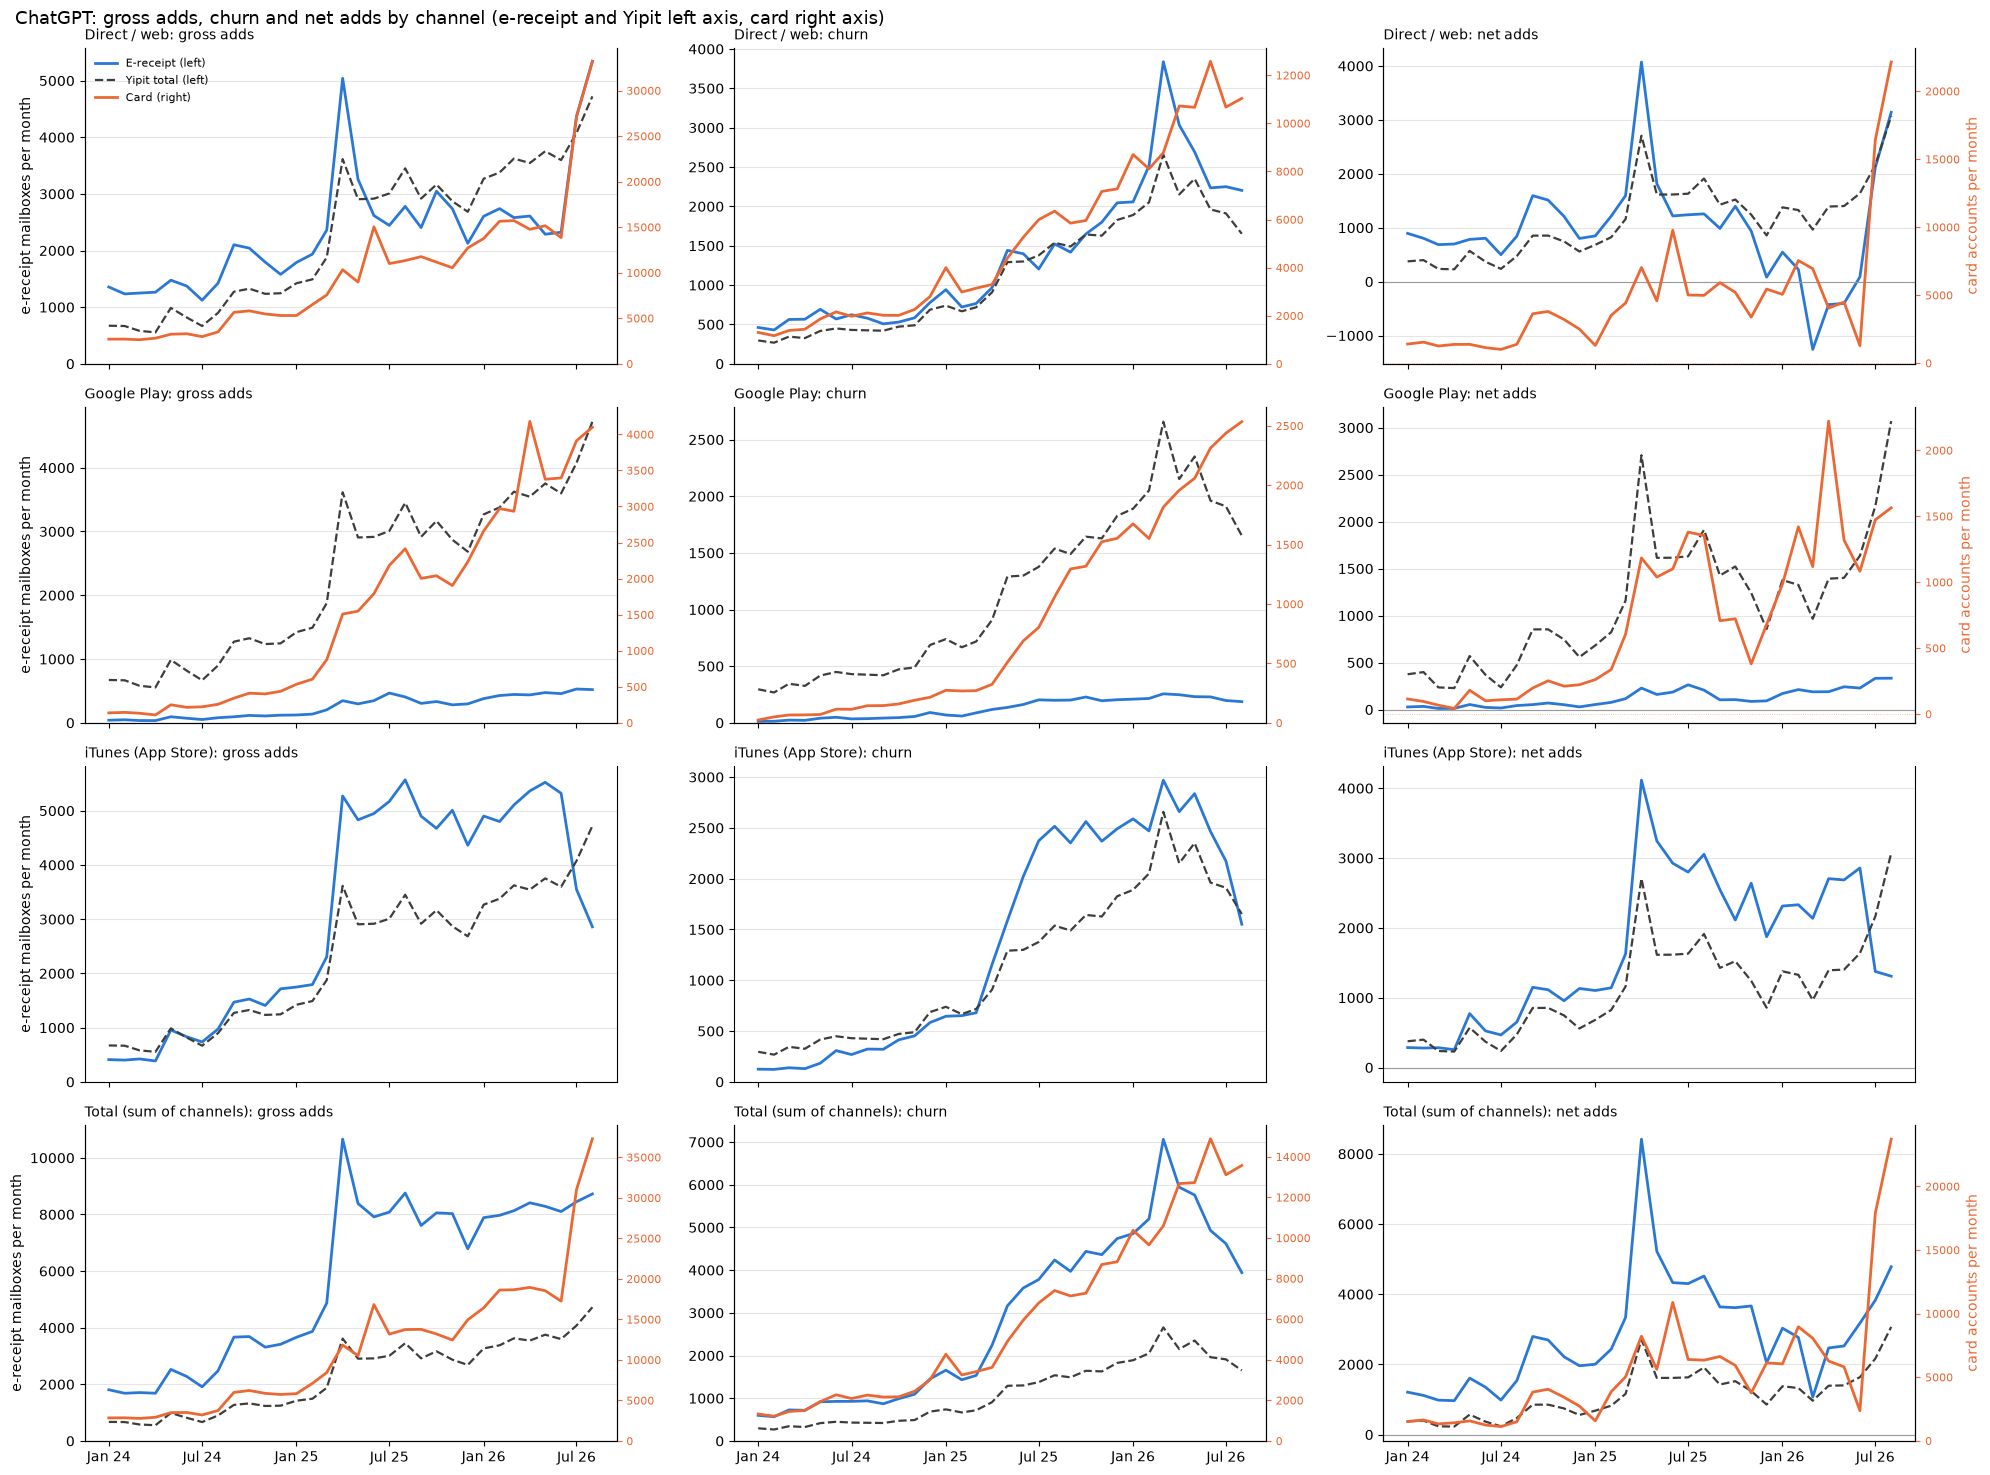

In [5]:
plot_provider("chatgpt")

In [6]:
summary("chatgpt")

C:\Users\fintan.creedon\code\exploration\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\fintan.creedon\code\exploration\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


**Finding: card and e-receipts agree on ChatGPT's trend until mid-2026, then diverge; Yipit tracks the e-receipts.**
- **Level:** cards see 4.2x the e-receipt web adds and 6.2x on Google Play. The two panels differ in size, and direct e-receipts carry only the sign-up email.
- **Trend:** monthly levels correlate (adds 0.82 web / 0.96 Play; churn 0.90 / 0.89), but month-on-month changes much less (adds 0.54 / 0.41, churn about 0).
- **Churn diverges from Mar 2026:** card web churn climbs from 8k to 11-12k a month, while e-receipt direct cancellations stay flat at about 2.2k. Direct sends no renewal receipts, so a lapse without a cancellation email is invisible on e-receipts.
- **Card web adds jump Jul-Sep 2026** (Plus 12k → 21k → 26k → 27k; Go 2k → 7k). The adds look like real paying subscribers: 76-80% are new to ChatGPT in the panel, they pay full price, they renew within 40 days at the usual rate (83%), and under 1% came from Google Play.
- **E-receipt direct adds surge at the same time** (2.3k → 4.4k → 5.3k), while **iTunes adds fall** (5.3k → 2.9k). The share of direct adds with an earlier iTunes ChatGPT subscription rises from 12% to 21-22%, and the share that cancelled iTunes within 60 days doubles (4.5% → 9%). Roughly 30% of the extra direct adds had been iTunes subscribers; the rest are new sign-ups going to the web rather than the App Store.
- **So this is mostly a shift of channel, not extra subscribers.** E-receipt total adds rise only modestly, in line with Yipit (+30% Jun-Aug). Cards can't see Apple, so they record the move to the web as growth. A card-only ChatGPT series overstates growth whenever subscribers move from iTunes to the web.
- **Yipit vs e-receipt totals:** adds 0.97, churn 1.00. This is consistent with Yipit being an e-receipt panel. Card vs Yipit: 0.91 / 0.93.

## 2. Claude

**Channels seen:** card = web + Google Play. E-receipt = direct, Google Play, iTunes. Yipit = provider total.

**Card filter** (`../filters/claude.py`). Tagged rows come from `TXNS_CORE_V` (brand 29847 ANTHROPIC). Google Play and `CLAUDEAI SUBSCRIPTION` rows are untagged and come from Omega.
- **Web:** `CLAUDE.AI SUBSCRIPTION` (to Jun 2026), `ANTHROPIC* CLAUDE SUB` / `ANTHROPIC* CLAUDE` (from 30 May 2026), and issuer truncations. Bare `ANTHROPIC` is API credits and is excluded. Team and certification charges are excluded.
- **Google Play:** `GOOGLE *CLAUDE BY ANTH…`, at Play price points.
- **Plans:** Pro monthly/annual and Max 5x/20x. Pro annual and Max 20x share a price ($200); they are split by whether the account repeats that charge about 2 months apart.

**E-receipt filter**
- **Direct:** the Anthropic (20127) `Pro subscription` / `Max subscription` welcome, and a priced `Payment` of $20/$100/$200 each month. Churn comes from `Anthropic Cancellation` (20139) emails. A cancellation within 3 days of a welcome for a different tier is a tier switch and is not churn.
- **Google Play:** a priced `(Claude by Anthropic) Auto-renewing subscription` receipt. Churn comes from Play cancellations naming Claude by Anthropic.
- **iTunes:** a confirmation or priced receipt for the `Claude by Anthropic` app (credits excluded, annual plans use 400 days). Churn comes from `iTunes Cancellation`.

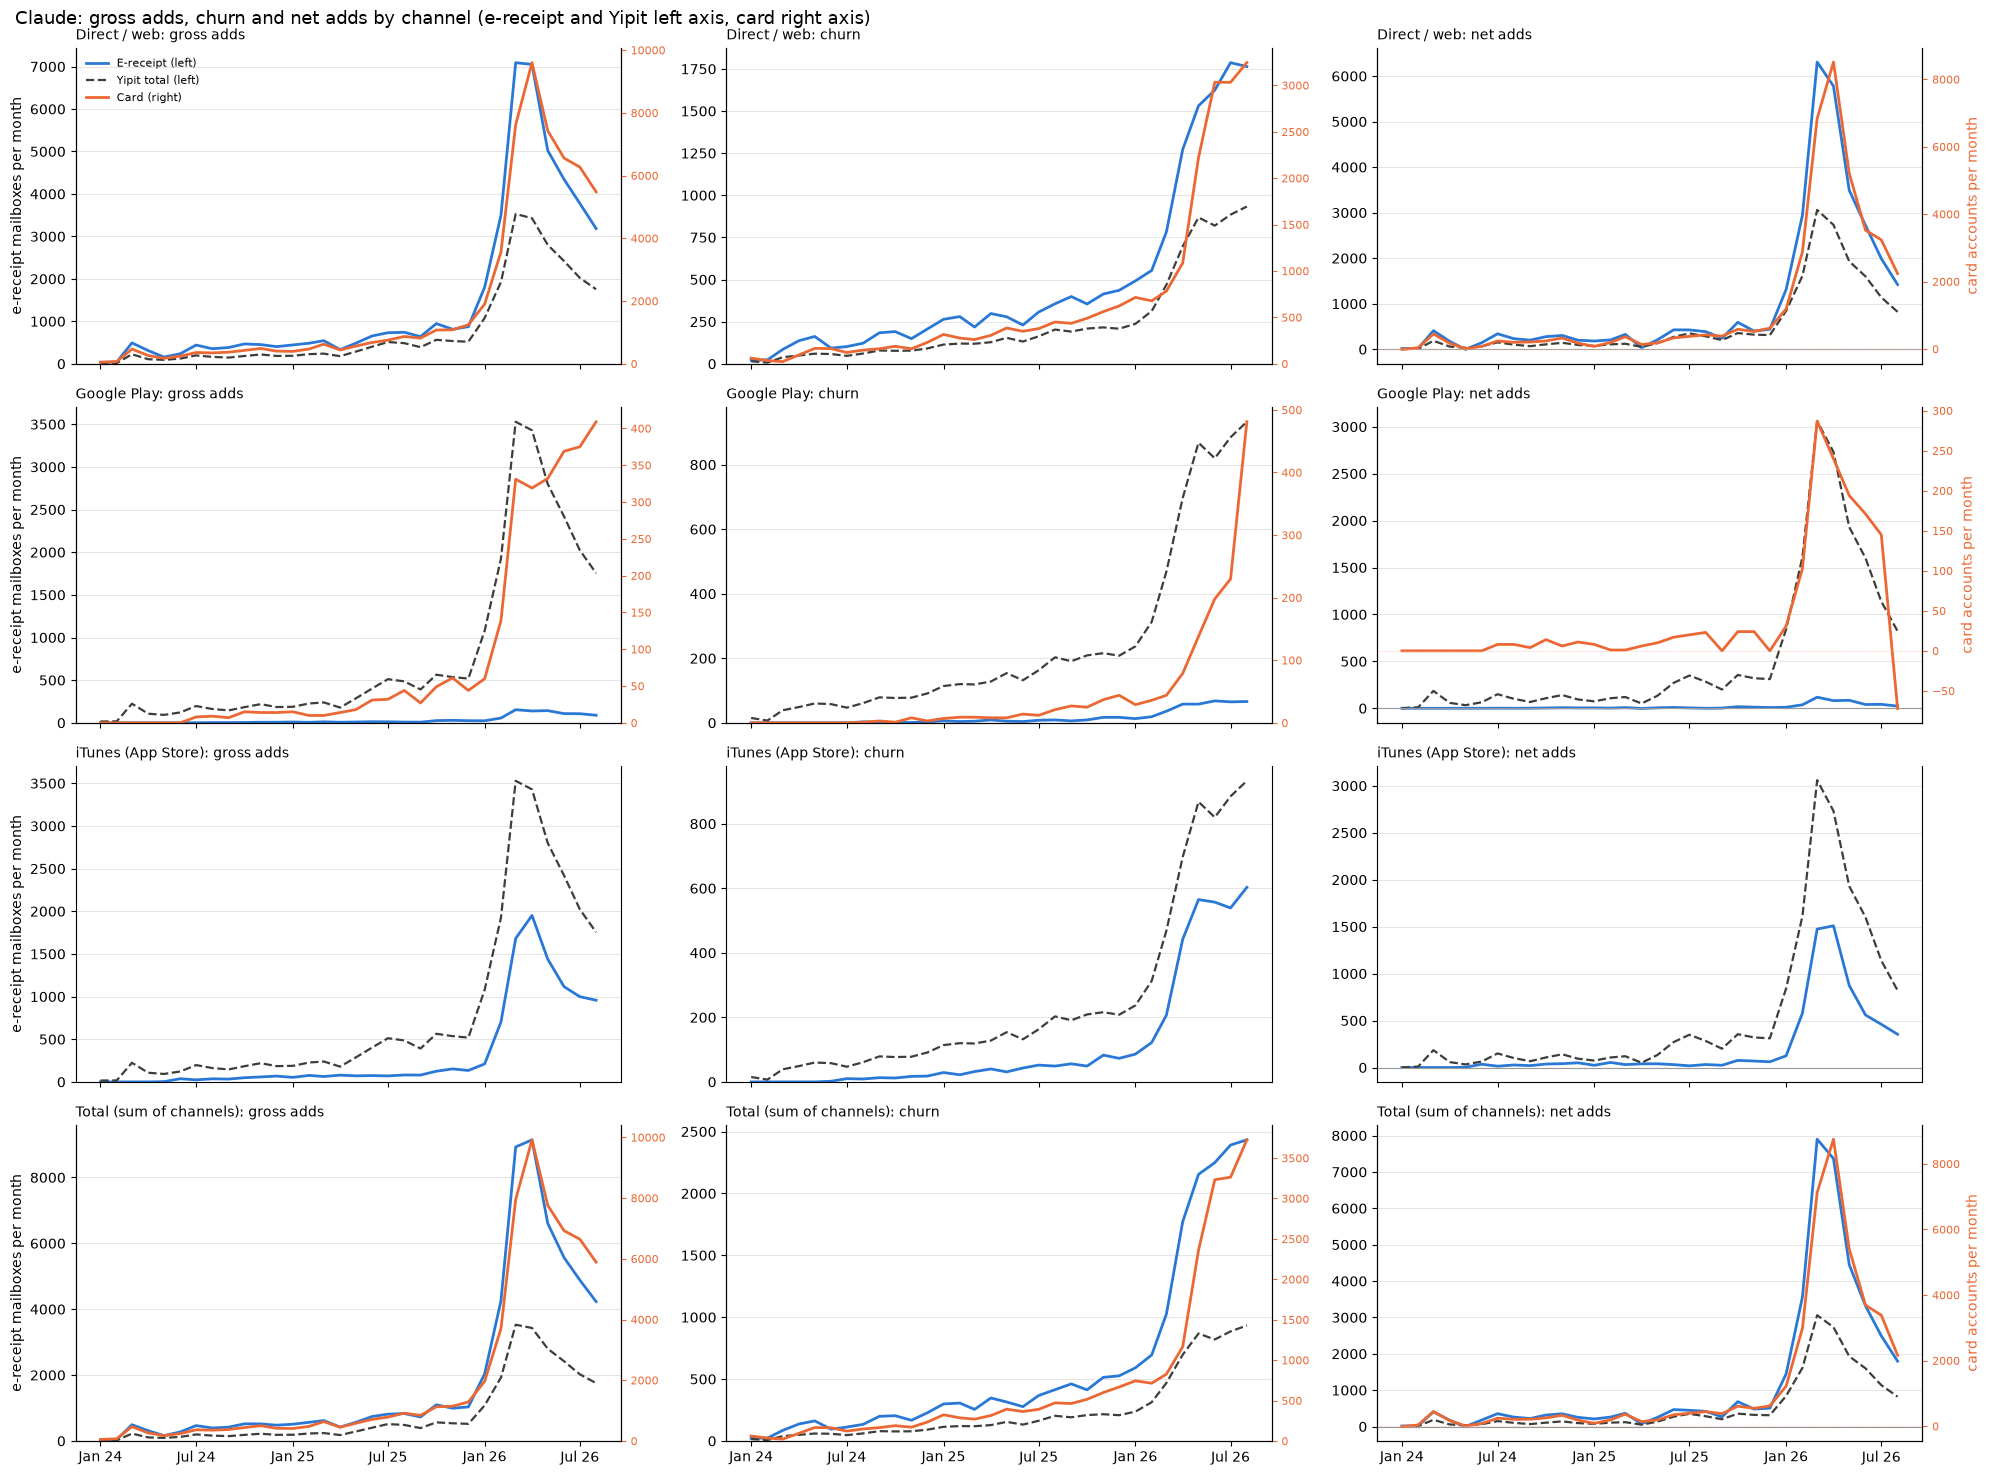

In [7]:
plot_provider("claude")

In [8]:
summary("claude")

C:\Users\fintan.creedon\code\exploration\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\fintan.creedon\code\exploration\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


**Finding: Claude is where the two sources agree. Both levels and trends match.**
- **Totals:** card / e-receipt = 1.09 on adds and 1.17 on churn. Correlation 0.98 / 0.96; month-on-month 0.94 / 0.48. Net adds correlation 0.98.
- **Web:** adds ratio 1.29, correlation 0.98 (MoM 0.92). The e-receipt panel sees direct payments monthly, so both sources measure the same thing.
- **Churn diverges from Apr 2026:** by Aug, card web churn is about 3.3k against 1.8k e-receipt cancellations. That is the gap between lapses (card) and cancellation emails, which grows after the Feb-Mar 2026 sign-up wave. On Google Play, card churn jumps in Aug 2026 (231 → 482). That matches the card's missing Google-billed charges (see Gemini) rather than a real change.
- **Yipit** matches the e-receipts almost exactly (correlation 1.00 / 1.00).

## 3. Gemini (Google AI plans)

**Channels seen:** card = **one Google One line, reported as web**. The card descriptor (`GOOGLE *Google One`) does not show whether the plan was bought on the web or in the Play Store, so card Gemini sits in the Direct/web row and covers e-receipt direct **and** Google Play. E-receipt = direct, Google Play, iTunes. Yipit = provider total.

**Card filter** (`../filters/gemini.py`). Tagged rows come from `TXNS_CORE_V` (brand 32111 GOOGLE ONE, above $3.50). Three untagged forms come from Omega:
- the SKU-code descriptors (`G1AI` / `G1SK`) used from 15 Sep 2026;
- other untagged `GOOGLE…ONE` merchids such as `GOOGLE ONE, MOUNTAIN VIEW, CA` (about 5k accounts a month since 2025, 12–13k in Jun–Aug 2026);
- the truncated generic `GOOGLE *GOOGLE MOUNTAIN VIE` (decision 26 Oct). It carried most of the Google One charges missing in Jul–Aug 2026. About 48% of its charges sit at Google One prices; the rest is other Google billing, which can read as Gemini when the amount matches an AI price.
- Google One / Google Storage charges at **AI-tier prices**: AI Premium/Pro, Ultra, AI Plus. Google bills AI and storage plans under the same descriptor, so the tier is read from the amount. Where an AI price equals a storage price, the account's own payment gaps decide the cadence.
- **2TB counts as AI Plus from 27 Jan 2026** (plan `ai_plus_2tb`, an earlier card decision). Existing 2TB payers therefore become card gross adds from late Jan 2026.

**E-receipt filter**
- **Direct:** Google One (20187) `Welcome…` emails naming an AI plan. Churn comes from Google One Cancellation (20191) `ended` / `cancelled` emails naming an AI plan (not `trial has ended`). About 64% of direct welcomes duplicate a Google Play receipt for the same sign-up (channel notebook).
- **Google Play:** a priced `(Google One)` receipt naming an AI plan. Play cancellations rarely name the plan, so a cancellation counts as AI if it names one, or if the mailbox's last Google One Play receipt in the previous 75 days was an AI plan. The May–Jun 2026 rename of 2TB to `Google AI Plus (2 TB)` at the same price **counts as an add** (decision 26 Oct, as Yipit does). Cards pick up the same 2TB subscribers earlier, from the 27 Jan 2026 rule date.
- **iTunes:** confirmations and priced receipts naming a Google AI plan. Churn comes from `iTunes Cancellation`.

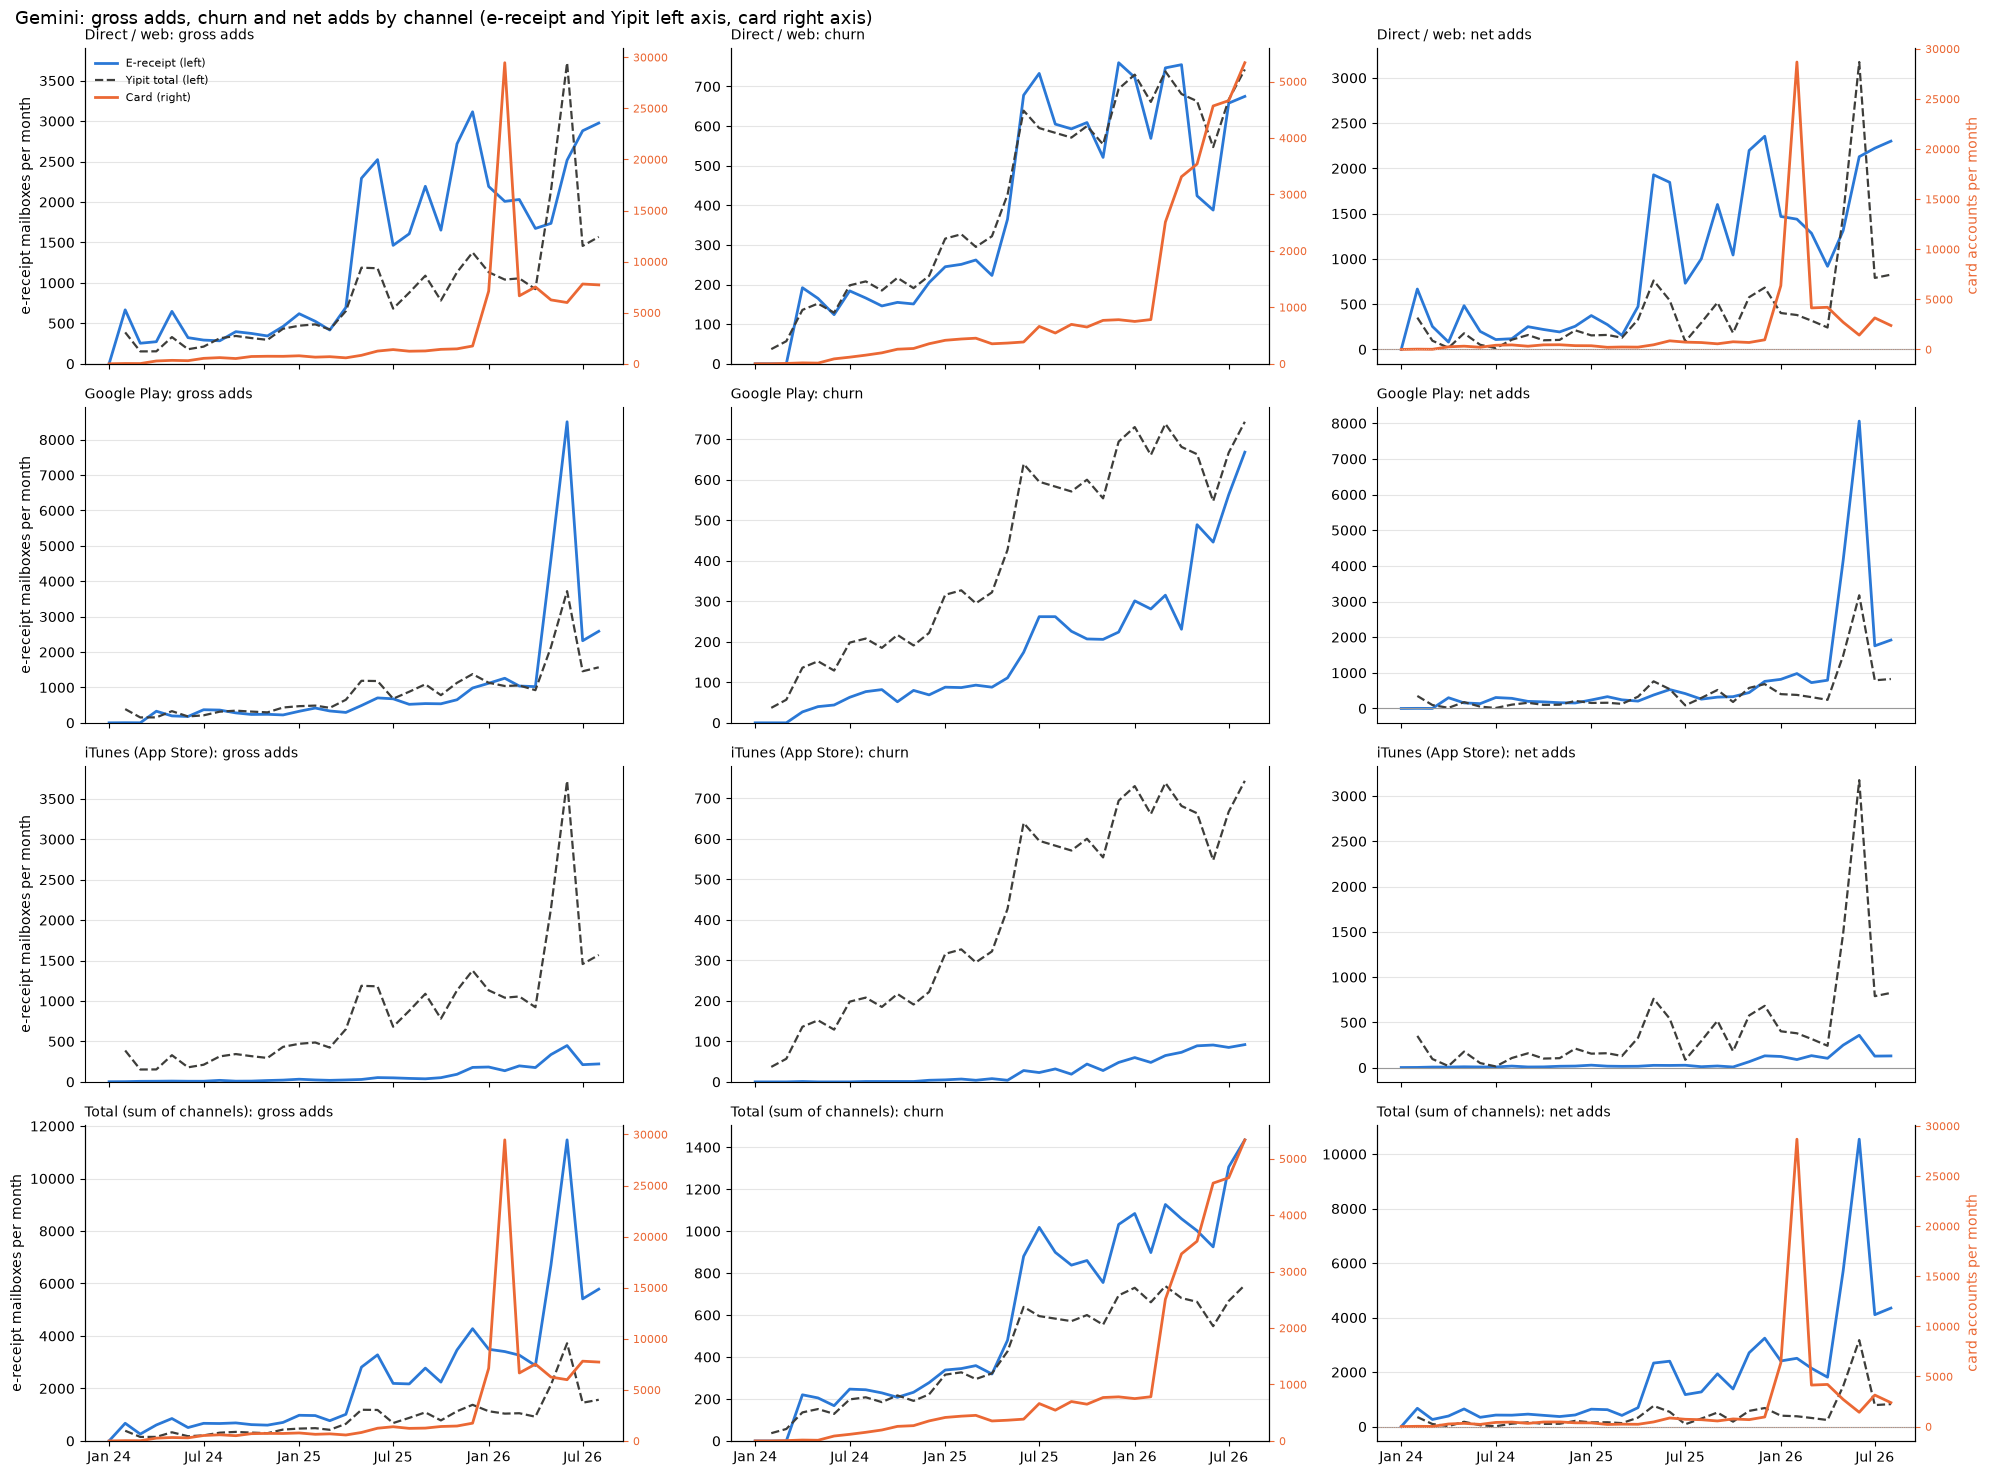

In [9]:
plot_provider("gemini")

In [10]:
summary("gemini")

C:\Users\fintan.creedon\code\exploration\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\fintan.creedon\code\exploration\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


**Finding: with the missing Google One descriptors added, card Gemini is continuous, but the 2TB subscribers enter the two sources at different times.**
- **The Jul-Aug 2026 card hole is closed.** Card paying accounts now run 51.0k (Jun) → 53.5k (Jul) → 54.0k (Aug) → 58.7k (Sep), and August churn falls from 15k to 5.3k. The missing charges were on the truncated `GOOGLE *GOOGLE MOUNTAIN VIE` (11-12k accounts a month in Jul-Aug) and untagged `GOOGLE ONE, …` merchids (added 26 Oct).
- **False-positive risk:** 6% of card Gemini accounts (6k of 100k) appear only under the generic `GOOGLE *GOOGLE MOUNTAIN VIE`. They are 14% of August adds and could be other Google charges at AI prices.
- **2TB timing:** cards add the 2TB subscribers in Jan-Feb 2026 (about 29k in Feb, the 27 Jan rule date). The e-receipts add them in May-Jun 2026 (Google Play 8.5k in Jun), when the receipt text changed to `Google AI Plus (2 TB)`. Yipit also shows them in Jun. So card and e-receipt adds correlate poorly (0.42), even though both count the same subscribers.
- **Card churn rises from Mar 2026** (about 1k → 5.3k a month by Aug). This is the larger 2TB base churning at storage-plan rates; e-receipt churn rises less (about 1.0k → 1.4k).
- **E-receipt vs Yipit** now match on adds (0.99, up from 0.82 before the rename was counted) and on churn (0.97).

## 4. Perplexity

**Channels seen:** card = web + Google Play. E-receipt = direct, Google Play, iTunes. Yipit = provider total.

**Card filter** (`../filters/perplexity.py`). Tagged rows come from `TXNS_CORE_V` (brand 29069). The brandless Jun–Oct 2026 descriptor (`PRO WWW.PERPLEXIT CA`) and Google Play rows are untagged and come from Omega.
- **Web:** `WWW.PERPLEXITY.AI` / `PERPLEXITY PRO`, including PayPal. **Google Play:** `GOOGLE *PERPLEXITY`.
- **Plans:** Pro monthly/annual, Max monthly/annual and discounted Pro. Enterprise seats, API and Computer credits, merchandise and name collisions are excluded.

**E-receipt filter**
- **Direct:** Perplexity (4212) sends **only** a welcome (`Welcome to Perplexity Pro/Max`), with no paid receipts; welcomes are promo-heavy. Churn comes from Perplexity Cancellation (4213) emails, excluding `trial has ended`.
- **Google Play:** a priced `Perplexity Pro/Max (Perplexity…) Auto-renewing subscription` receipt. Churn comes from Play cancellations.
- **iTunes:** confirmations and priced receipts for `Perplexity Pro/Max`. Churn comes from `iTunes Cancellation`.

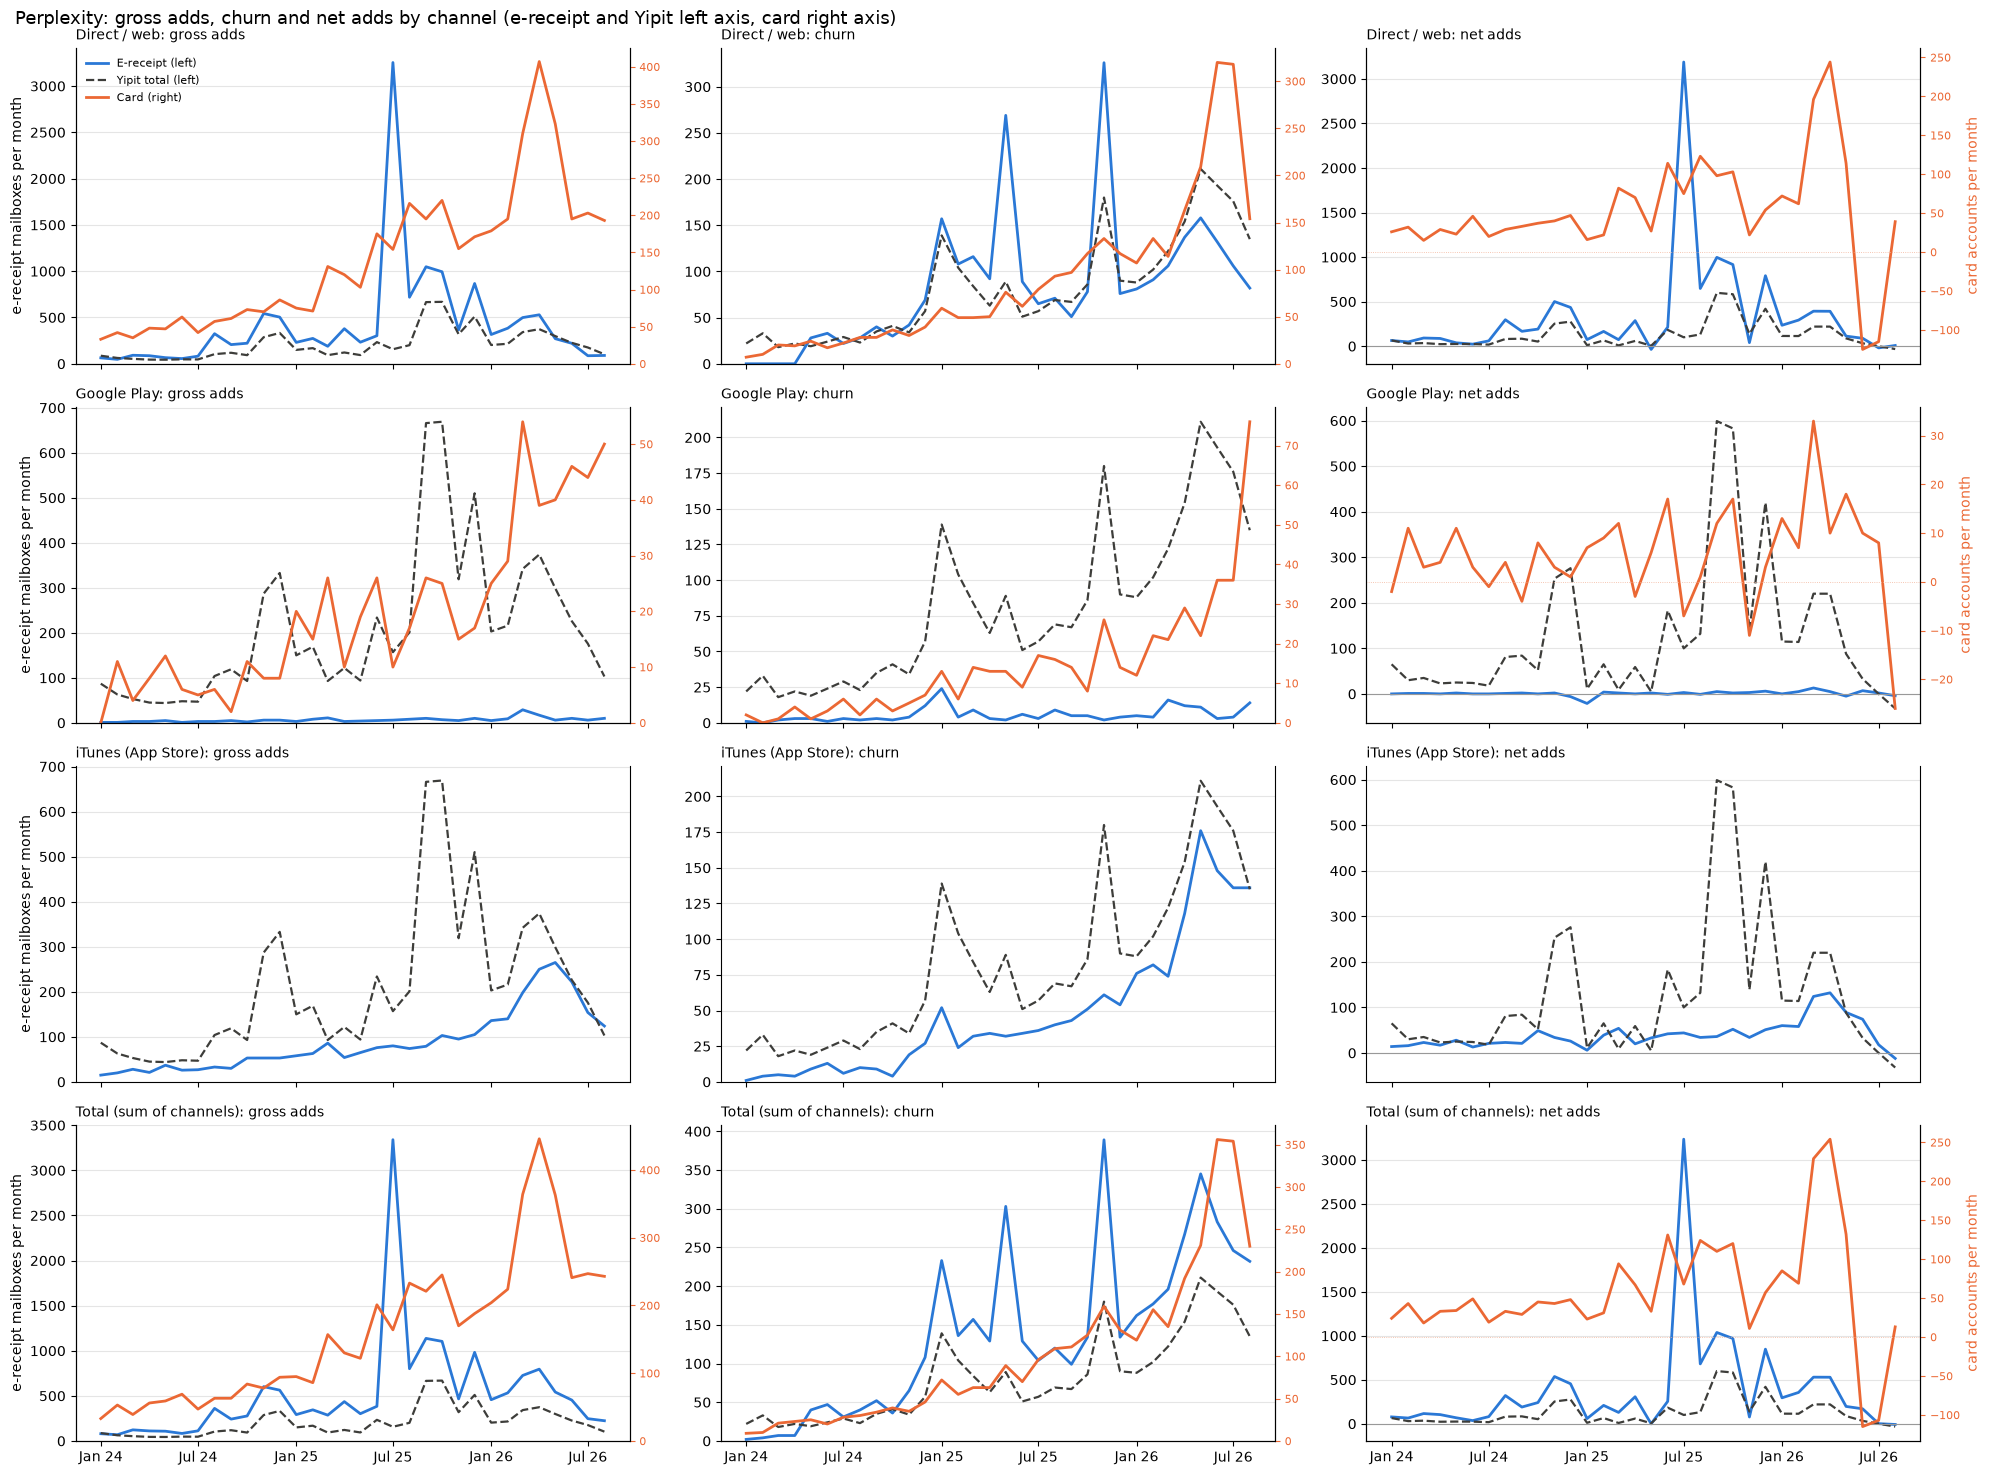

In [11]:
plot_provider("perplexity")

In [12]:
summary("perplexity")

C:\Users\fintan.creedon\code\exploration\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\fintan.creedon\code\exploration\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


**Finding: Perplexity is too thin and too promo-driven for either source to read cleanly.**
- **Direct adds:** e-receipts see 3x the card's adds (13.6k vs 4.4k). Direct welcome emails include promos and trials that never reach a paid charge, e.g. the Jul 2025 spike of 3.3k. Card adds are paid charges only.
- **Churn levels are similar** (card / e-receipt 1.04 on web), but monthly correlation is only 0.46.
- **Google Play** is under 60 adds a month on both sources: noise.
- **Yipit** correlates with e-receipt churn (0.93) but not with adds (0.41). Yipit's own adds are volatile (e.g. Sep 2025 660 a month).

## 5. Grok (SuperGrok + X Premium+)

**Channels seen:** card = web + Google Play. E-receipt = Google Play + iTunes only; there are no direct receipts from xAI or X Corp, so the Direct/web row is card only. **No Yipit series:** Yipit's US Subscriber Behavior block has no Grok.

Grok is one line: SuperGrok (billed by xAI) plus X Premium+ (billed by X Corp). An account paying for both counts once per channel.

**Card filter** (`../filters/grok.py`). X.AI and X.COM are not in the `TXNS_CORE` brand selection, so **every Grok row comes from Omega `TRANS_V1_0`** by descriptor (2022 panel, affected accounts excluded).
- **SuperGrok / Heavy / Lite / Plus:** `GROK XAI`, `XAI LLC`, `X.AI/…`. Google Play: `GOOGLE *GROK`.
- **X Premium+:** `X CORP. PAID FEATURES`, `TWITTER PAID FEATURES` and Omega's masked form `CORP. PAID FEATURES`. Google Play: `GOOGLE *X CORP` / `TWITTER`. Basic and Premium (not Plus) share the descriptor and are excluded by price.

**E-receipt filter**
- **Google Play:** a priced `SuperGrok (Grok AI)` or `Premium+ (X)` auto-renewing receipt. Churn comes from Play cancellations from `X.AI Corp` / `SpaceXAI LLC` / naming SuperGrok. X cancellations (`X subscription from Twitter Inc`) don't name the tier, so they count only when the mailbox's last X Play receipt in the previous 75 days was Premium+.
- **iTunes:** confirmations and priced receipts for SuperGrok or `X : X Premium Plus`. Churn comes from `iTunes Cancellation` for those.
- Compared with the channel notebook, two things are added: X Premium+, and the `SpaceXAI LLC` cancellation sender (listed in `../filters_receipts/grok_report.md`).

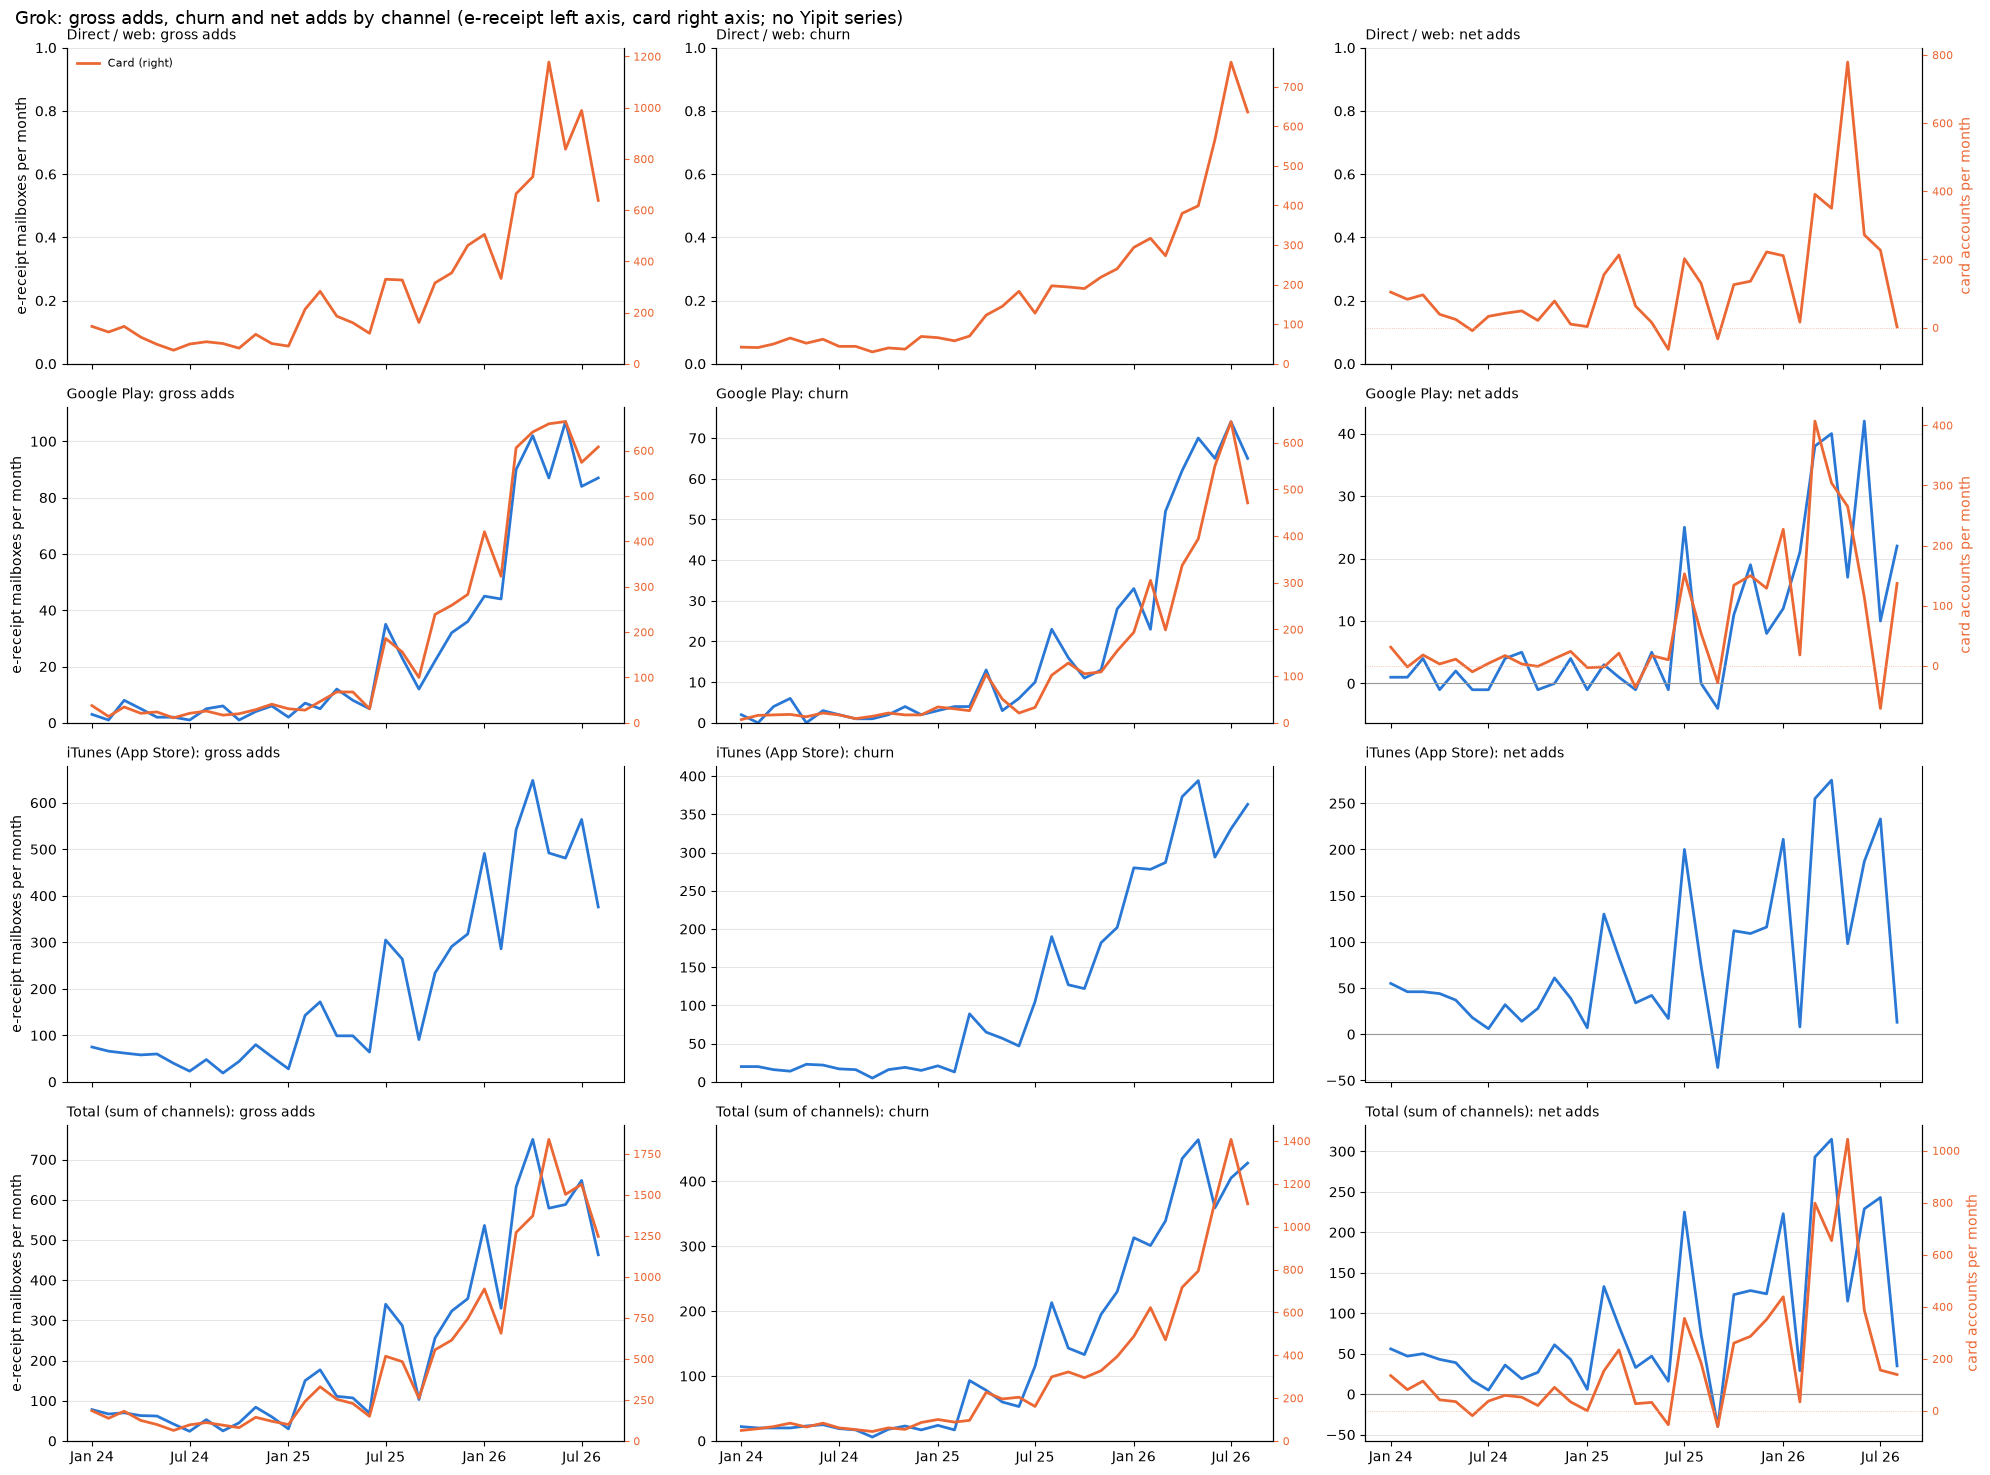

In [13]:
plot_provider("grok")

In [14]:
summary("grok")

**Finding: card and e-receipt Grok trends agree on Google Play, and each source has a channel the other can't see.**
- **Google Play:** card / e-receipt = 7.1x on adds and 6.9x on churn, with level correlations 0.99 and 0.94.
- **Cards alone see web billing** (~1k adds a month in 2026); **e-receipts alone see iTunes** (~500 a month). There's no Yipit series to check against.
- **Totals** (sum of channels) correlate 0.96 on adds and 0.90 on churn, but each total is built from a different channel mix.

## 6. Summary across providers

In [15]:
rows = []
for p in R.PROVIDERS:
    for ch in ROWS:
        e, c = series(rec, p, ch, "gross_adds"), series(card, p, ch, "gross_adds")
        ec, cc = series(rec, p, ch, "churn"), series(card, p, ch, "churn")
        rows.append({"provider": R.NAMES[p], "channel": ROWS[ch],
                     "adds: card / e-receipt": c.sum() / e.sum() if e.sum() and c.sum() else np.nan,
                     "adds corr": e.corr(c) if e.std() and c.std() else np.nan,
                     "churn: card / e-receipt": cc.sum() / ec.sum() if ec.sum() and cc.sum() else np.nan,
                     "churn corr": ec.corr(cc) if ec.std() and cc.std() else np.nan,
                     "net corr": (e - ec).corr(c - cc) if (e - ec).std() and (c - cc).std() else np.nan})
t = pd.DataFrame(rows).set_index(["provider", "channel"])
t.style.format("{:.2f}", na_rep="")

**Summary for the web-app decision**
| Provider | Level agreement | Trend agreement | Main issue |
|---|---|---|---|
| Claude | Close (1.1-1.2x) | Strong (0.96-0.98, MoM adds 0.94) | Card churn runs ahead of cancel emails from Apr 2026 |
| ChatGPT | Card 4-6x | Levels 0.8-0.96, MoM weak | Direct e-receipts are sign-up only; cards miss iTunes, so the Jul-Sep 2026 iTunes → web shift reads as card growth |
| Gemini | Card 1.3x adds, 1.8x churn | Weak (0.42 adds) | 2TB subscribers enter cards in Feb 2026 but e-receipts and Yipit in Jun 2026; generic Google descriptor adds some false positives |
| Grok | Card 7x on Play | Strong on Play | Each source covers a channel the other doesn't (web vs iTunes) |
| Perplexity | Mixed | Weak | Small samples; promo-heavy direct welcomes |

- **Yipit tracks the e-receipts** wherever both exist (churn correlation 0.93-1.00), as expected for an e-receipt panel.
- **Card descriptor gaps read as churn.** The ChatGPT `CHATGP` and Gemini `GOOGLE *GOOGLE MOUNTAIN VIE` fixes both closed holes that had shown as churn followed by re-adds. The Claude Google Play churn jump in Aug 2026 (231 → 482) may be the same issue and is unchecked.
- **Cards miss Apple**, so a shift between iTunes and the web (ChatGPT, Jul-Sep 2026) reads as card growth or decline.

In [16]:
# exports for the web app
R.CACHE.mkdir(parents=True, exist_ok=True)
pd.concat([card.assign(source="card"), rec.assign(source="e-receipt"), yip.assign(source="yipit", channel="total")]) \
  .assign(month=lambda d: d.month.astype(str)).to_parquet(R.CACHE / "monthly.parquet", index=False)
print("wrote", R.CACHE / "monthly.parquet")

wrote C:\Users\fintan.creedon\code\exploration\ai\.cache\card_ereceipt\monthly.parquet
